<p align="center"><b><font size="5">Predicción del SP500 con modelo SARIMA y LSTM</font></b></p>

<p align="center"><b><font size="4">Descripción general:</font></b></p>

La meta del proyecto es crear y desplegar un modelo predictivo del SP500. Para esto se comparará un modelo clásico de machine learning (SARIMA) con un modelo de redes neuronales (LSTM).

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error
from arch import arch_model
from statsmodels.tools.sm_exceptions import ValueWarning
import warnings
from datetime import datetime

Durante la ajecución de SARIMAX se presentaron algunos warnings, se ocultaron aquellos que no afectan al resultado final ni la validez del modelo:

-Non-stationary starting autoregressive parameters y Non-invertible starting MA parameters indican que los valores iniciales propuestos para la optimización no cumplen las restricciones del modelo. De esta manera statsmodels los reemplaza automáticamente por valores válidos (ceros) y continúa la estimación.

-ValueWarning: No supported index is available: Se debe a que las series bursátiles contienen huecos por los fines de semana y días festivos. Al hacerce las predicciones por pasos sucesivos, el warning no afecta a los resultados.

-FutureWarning: No supported index is available: En la versión actual de statsmodels se permite trabajar con frecuencias que no puedan inferirse automáticamente. Mientras que una nueva versión statsmodels no cambie esto, el modelo no se verá afectado.

In [2]:
warnings.filterwarnings("ignore", category=ValueWarning)

warnings.filterwarnings(
    "ignore", message="A date index has been provided, but it has no associated frequency information*")

warnings.filterwarnings(
    "ignore", message="Non-stationary starting autoregressive parameters*")

warnings.filterwarnings(
    "ignore", message="Non-invertible starting MA parameters*")

warnings.filterwarnings(
    "ignore", message="No supported index is available*")

Se descargan los últimos tres años de sp500. Se verifican datos faltantes, duplicados y el tipo de dato. Finalmente se usa resamble para crear el dataset con solo los valores de cierre y el índice en días laborales.

In [3]:
df = yf.download('^GSPC', period='3y')  
print(df.info())
print("Valores faltantes", df.isna().sum())
print("Valores duplicados", df.duplicated().sum())
daily = df['Close'].resample("B").mean()
print("Datos faltantes después de resamble", daily.isna().sum())

[*********************100%***********************]  1 of 1 completed

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 754 entries, 2023-10-30 to 2026-10-30
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, ^GSPC)   754 non-null    float64
 1   (High, ^GSPC)    754 non-null    float64
 2   (Low, ^GSPC)     754 non-null    float64
 3   (Open, ^GSPC)    754 non-null    float64
 4   (Volume, ^GSPC)  754 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 35.3 KB
None
Valores faltantes Price   Ticker
Close   ^GSPC     0
High    ^GSPC     0
Low     ^GSPC     0
Open    ^GSPC     0
Volume  ^GSPC     0
dtype: int64
Valores duplicados 0
Datos faltantes después de resamble Ticker
^GSPC    31
dtype: int64


Eliminamos los valores faltantes (días festivos que no registran entradas de cierre) y realizamos seasonal_decompose. Aunque los índices bursátiles no suelen presentar una estacionalidad anual estable, se verifica si existen patrones en los residuos para saber si hacer pruebas para los mismos. 

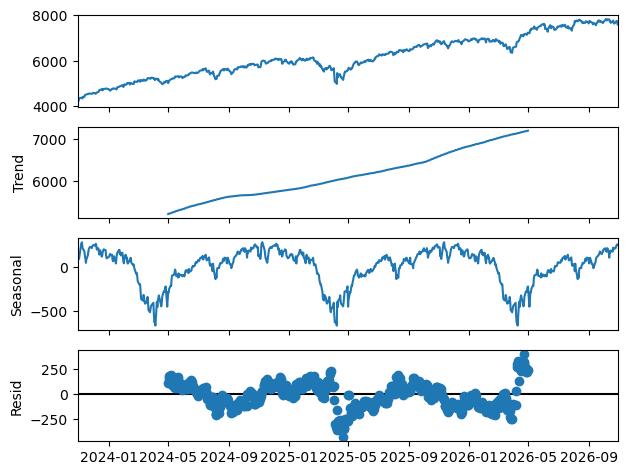

In [4]:
daily_drop = daily.copy()
daily_drop = daily_drop.dropna()
result_drop = seasonal_decompose(daily_drop, model="additive", period=252)
result_drop.plot()
plt.show()

Los residuos no parecen estar distribuidos completamente al azar, por lo que se incluye una prueba de acorr_ljungbox para verificar que la estructura del índice está siendo explicado por el modelo.

-Se construyen dos modelos, uno para precios y el otro para retornos. 

-Se prueban los modelos con dos dataset, uno con train de 2 años y medio y test de 6 meses, el otro con un train de 1 año y dos meses de test.

In [5]:
daily_precios = np.log(daily_drop)
daily_retornos_ = np.log(daily_drop).diff()
daily_retornos = daily_retornos_.dropna()

train_precios_years_3 = daily_precios.iloc[:627]
test_precios_years_3 = daily_precios.iloc[627:]

train_precios_meses_12 = daily_precios.iloc[-(252+42):-42]
test_precios_meses_12 = daily_precios.iloc[-42:]

train_retornos_years_3 = daily_retornos.iloc[:627]
test_retornos_years_3 = daily_retornos.iloc[627:]

train_retornos_meses_12 = daily_retornos.iloc[-(252+42):-42]
test_retornos_meses_12 = daily_retornos.iloc[-42:]

In [6]:
def sarima_precios(train, test, nombre):

    resultados = {}
    
    model = SARIMAX(train, order=(1,1,2), seasonal_order=(1,0,1,5))
    fit = model.fit(disp=False)
    
    forecast = fit.get_forecast(steps=len(test))
    pred_mean = forecast.predicted_mean
    pred_ci = forecast.conf_int(alpha=0.01)

    residuals = fit.resid

    lb_test = acorr_ljungbox(residuals, lags=[20], return_df=True)
    
    rmse = np.sqrt(mean_squared_error(test.values, pred_mean.values))
    mae = mean_absolute_error(test.values, pred_mean.values)
    mape = np.mean(
    np.where(test.values != 0,
             np.abs((test.values - pred_mean.values) / test.values),
                 0)
            ) * 100

    resultados = {"Modelo": nombre,
        "RMSE": rmse,
    "MAE": mae,
    "MAPE": mape,
    "Valor-p":lb_test["lb_pvalue"].values}

    return resultados

In [8]:
def sarima_retornos(train, test, nombre):

    resultados = {}
    
    model = SARIMAX(train, order=(1, 0, 2), seasonal_order=(1,0,1,5))
    fit = model.fit(disp=False)
    
    forecast = fit.get_forecast(steps=len(test))
    pred_mean = forecast.predicted_mean
    pred_ci = forecast.conf_int(alpha=0.01)

    residuals = fit.resid

    lb_test = acorr_ljungbox(residuals, lags=[20], return_df=True)
    
    rmse = np.sqrt(mean_squared_error(test.values, pred_mean.values))
    mae = mean_absolute_error(test.values, pred_mean.values)
    mape = np.mean(
    np.where(test.values != 0,
             np.abs((test.values - pred_mean.values) / test.values),
                 0)
            ) * 100

    resultados = {"Modelo": nombre,
        "RMSE": rmse,
    "MAE": mae,
    "MAPE": mape,
    "Valor-p":lb_test["lb_pvalue"].values}
    
    return resultados

In [39]:
modelo_precios_3_tears = sarima_precios(train_precios_years_3, test_precios_years_3, "Precios 3 años")
modelo_precios_1_tears = sarima_precios(train_precios_meses_12, test_precios_meses_12, "Precios un año")
modelo_retornos_3_tears = sarima_retornos(train_retornos_years_3, test_retornos_years_3, "Retornos 3 años")
modelo_retornos_1_tears = sarima_retornos(train_retornos_meses_12, test_retornos_meses_12, "Retornos un año")

datos= [modelo_precios_3_tears, modelo_precios_1_tears, modelo_retornos_3_tears, modelo_retornos_1_tears]
tabla_modelos = pd.DataFrame(datos)
tabla_modelos

,Modelo,RMSE,MAE,MAPE,Valor-p
0,Precios 3 años,0.053023,0.049275,0.551149,[1.0]
1,Precios un año,0.012983,0.010868,0.120958,[1.0]
2,Retornos 3 años,0.007641,0.005952,105.661181,[0.21054032318879468]
3,Retornos un año,0.006717,0.005540,134.634052,[0.9376413755645224]


In [23]:
parámetros_p

,Order,RMSE,AIC,Valor-p,Converged
6,"(1, 1, 2)",0.008123,-1702.235289,1.0,True
7,"(2, 1, 2)",0.008133,-1700.209321,1.0,False
2,"(1, 1, 1)",0.009044,-1701.623228,1.0,True
0,"(0, 1, 1)",0.009045,-1703.636571,1.0,True
3,"(2, 1, 0)",0.009105,-1702.069390,1.0,False
1,"(1, 1, 0)",0.009125,-1704.139953,1.0,True
5,"(2, 1, 1)",0.009129,-1700.389247,1.0,True
4,"(0, 1, 2)",0.009160,-1702.599675,1.0,True


In [19]:
parámetros_t

,Order,RMSE,AIC,Valor-p,Converged
1,"(1, 0, 0)",0.006517,-1711.161344,0.884252,True
0,"(0, 0, 1)",0.006517,-1711.167363,0.884322,True
2,"(1, 0, 1)",0.006517,-1709.167950,0.884360,True
3,"(2, 0, 0)",0.006522,-1709.591936,0.916362,True
5,"(2, 0, 1)",0.006528,-1707.880671,0.917159,True
4,"(0, 0, 2)",0.006577,-1711.759509,0.953106,True
6,"(1, 0, 2)",0.006581,-1709.857599,0.954717,True
7,"(2, 0, 2)",0.006582,-1707.864024,0.954747,False


Los modelos trabajando con datos de un año tienen mejores métricas que con 3, lo que indica que la información reciente resulta más relevante en las predicciones. Las métricas del modelo de precios a doce años obtuvo un MAPE de 0.081, y el valor-p de Ljung-Box fue de 1.0, señalando que el error medio un poco mayor al 1% (0.120) y que los residuos no forman estructuras no analizadas (autocorrelación significativa). 

Con respecto al modelo de retornos a un año, las métricas de RMSE es de 0.006 y de MAE 0.005, de manera que los errores entre lo predicho y lo real es pequeño y el valor-p de Ljung-Box fue de 0.95, indicando que el modelo profundiza bien en la estructura temporal de la serie. La métrica de MAPE aunque se incluye en los retornos no se considera relevante ya que MAPE no trabaja bien con valores cercanos a 0, lo que pasa con los retornos.

Para elegir los parámetros se tomo como criterio la convergencia, que el valor-p de Ljung-Box fuera el más alto y que RMSE fuera el más bajo. Adicional se consideró la complegidad del modelo, aunque ninguno obtuvo una diferencia significativa, como se muestra en las tablas.

Seasonal_order se estabeció en (1,0,1,5), donde el periodo estacional de 5 observaciones representa los cinco días hábiles de negociación de una semana bursátil. Esta configuración se mantuvo constante durante la comparación de modelos para centrar el análisis en el efecto de los parámetros no estacionales.

Finalmente se grafican los resultados del train, test y las predicciones.

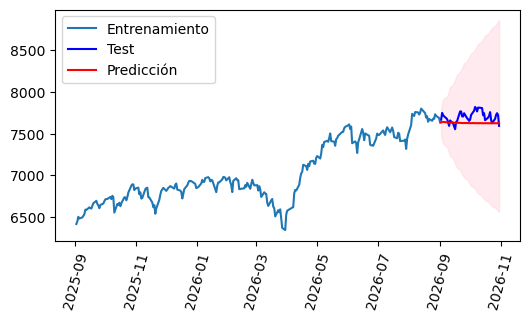

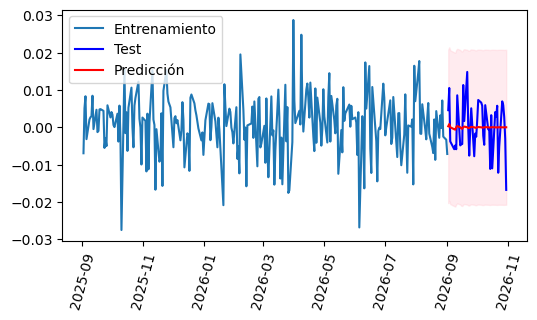

In [40]:
model_precios = SARIMAX(train_precios_meses_12, order=(1,1,2), seasonal_order=(1,0,1,5))
res_precios = model_precios.fit(disp=False)
forecast = res_precios.get_forecast(steps=len(test_precios_meses_12))
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int(alpha=0.01)

pred_mean_inv = np.exp(pred_mean)
pred_ci_inv = np.exp(pred_ci)
train_precios_inv = np.exp(train_precios_meses_12)
test_precios_inv =  np.exp(test_precios_meses_12)

plt.figure(figsize=(6,3))
plt.plot(train_precios_inv.index, train_precios_inv, label="Entrenamiento")
plt.plot(test_precios_inv.index, test_precios_inv, color = "blue", label = "Test")
plt.plot(test_precios_inv.index, pred_mean_inv, color="red", label= "Predicción")

plt.fill_between(test_precios_inv.index,
                 pred_ci_inv.iloc[:,0],
                 pred_ci_inv.iloc[:,1],
                 color="pink", alpha=0.3)

plt.xticks(rotation = 75)
plt.legend()
plt.show()

model_retornos = SARIMAX(train_retornos_meses_12, order=(1, 0, 2), seasonal_order=(1,0,1,5))
res_retornos = model_retornos.fit(disp=False)
forecast = res_retornos.get_forecast(steps=len(test_retornos_meses_12))
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int(alpha=0.01)


plt.figure(figsize=(6,3))
plt.plot(train_retornos_meses_12.index, train_retornos_meses_12, label="Entrenamiento")
plt.plot(test_retornos_meses_12.index, test_retornos_meses_12, color = "blue", label = "Test")
plt.plot(test_retornos_meses_12.index, pred_mean, color="red", label= "Predicción")

plt.fill_between(test_retornos_meses_12.index,
                 pred_ci.iloc[:,0],
                 pred_ci.iloc[:,1],
                 color="pink", alpha=0.3)

plt.xticks(rotation = 75)
plt.legend()
plt.show()

Se hace una prueba con ventanas moviles de 21 días de 1 año con el objetivo de medir la volatilidad promedio y verificar la estabilidad del modelo en distintos periodos. En el modelo final se incluirá la volatilidad para tener un ratio de retorno riesgo. 

In [60]:
def ventanas_p(data):
    resultados = []
    c = 0
    for _ in range(23):
        train_actual = data.iloc[0+c : 252+c]
        test_actual= data.iloc[252+c : (252+21)+c]

        model = SARIMAX(train_actual, order=(1,1,2), seasonal_order=(1,0,1,5))
        fit = model.fit(disp=False)
        
        forecast = fit.get_forecast(steps=len(test_actual))
        pred_mean = forecast.predicted_mean
        
    
        residuals = fit.resid
        lb_test = acorr_ljungbox(residuals, lags=[20], return_df=True)

        residuals_garch = residuals * 100
    
        garch = arch_model(residuals_garch, vol='GARCH', p=1, q=1)
        fit_garch = garch.fit(disp='off')
        forecast_vol = fit_garch.forecast(horizon=len(test_actual))
        pred_var = forecast_vol.variance.values[-1]   
        pred_vol = np.sqrt(pred_var) / 100
        promedio = np.mean(pred_vol)
        convergencia = fit.mle_retvals["converged"]
    
        rmse = np.sqrt(mean_squared_error(test_actual.values, pred_mean.values))
        mae = mean_absolute_error(test_actual.values, pred_mean.values)
        mape = np.mean(
        np.where(test_actual.values != 0,
                 np.abs((test_actual.values - pred_mean.values) / test_actual.values),
                     0)
                ) * 100
    
        resultados.append ({"Ventana": _,
            "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "Valor-p":lb_test["lb_pvalue"].iloc[0],
        "Variabilidad": promedio, 
        "Convergencia": convergencia})
        c += 21

    return pd.DataFrame(resultados)

def ventanas_r(data):
    resultados = []
    c = 0
    for _ in range(23):
        train_actual = data.iloc[0+c : 252+c]
        test_actual= data.iloc[252+c : (252+21)+c]

        model = SARIMAX(train_actual, order=(1,0,2), seasonal_order=(1,0,1,5))
        fit = model.fit(disp=False)
        
        forecast = fit.get_forecast(steps=len(test_actual))
        pred_mean = forecast.predicted_mean
        
    
        residuals = fit.resid
        lb_test = acorr_ljungbox(residuals, lags=[20], return_df=True)

        residuals_garch = residuals * 100
    
        garch = arch_model(residuals_garch, vol='GARCH', p=1, q=1)
        fit_garch = garch.fit(disp='off')
        forecast_vol = fit_garch.forecast(horizon=len(test_actual))
        pred_var = forecast_vol.variance.values[-1]   
        pred_vol = np.sqrt(pred_var) / 100
        promedio = np.mean(pred_vol)
        convergencia = fit.mle_retvals["converged"]
    
        rmse = np.sqrt(mean_squared_error(test_actual.values, pred_mean.values))
        mae = mean_absolute_error(test_actual.values, pred_mean.values)
        mape = np.mean(
        np.where(test_actual.values != 0,
                 np.abs((test_actual.values - pred_mean.values) / test_actual.values),
                     0)
                ) * 100
    
        resultados.append ({"Ventana": _,
            "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "Valor-p":lb_test["lb_pvalue"].iloc[0],
        "Variabilidad": promedio,
         "Convergencia": convergencia})
        c += 21

    return pd.DataFrame(resultados)

In [61]:
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [62]:
tabla_p = ventanas_p(daily_precios)
tabla_r = ventanas_r(daily_retornos)

In [63]:
print(tabla_p["Convergencia"].value_counts())
tabla_p.describe()

Convergencia
True     17
False     6
Name: count, dtype: int64


,Ventana,RMSE,MAE,MAPE,Valor-p,Variabilidad
count,23.00000,23.000000,23.000000,23.000000,23.0,23.000000
mean,11.00000,0.023065,0.020195,0.230502,1.0,0.012535
std,6.78233,0.016590,0.015280,0.174849,0.0,0.006163
min,0.00000,0.008451,0.007065,0.080019,1.0,0.007416
25%,5.50000,0.013244,0.010936,0.126297,1.0,0.008074
50%,11.00000,0.017616,0.014694,0.174202,1.0,0.011429
75%,16.50000,0.027806,0.025278,0.286349,1.0,0.014743
max,22.00000,0.071465,0.067096,0.756540,1.0,0.034600


In [64]:
print(tabla_p["Convergencia"].value_counts())
tabla_r.describe()

Convergencia
True     17
False     6
Name: count, dtype: int64


,Ventana,RMSE,MAE,MAPE,Valor-p,Variabilidad
count,23.00000,23.000000,23.000000,23.000000,23.000000,23.000000
mean,11.00000,0.009165,0.006895,184.403552,0.609377,0.009252
std,6.78233,0.004919,0.003093,275.891672,0.216591,0.001977
min,0.00000,0.003987,0.003388,99.038742,0.097972,0.006647
25%,5.50000,0.006419,0.004984,100.992201,0.486819,0.008236
50%,11.00000,0.008681,0.006411,112.926806,0.658485,0.008959
75%,16.50000,0.009218,0.007413,134.496624,0.742253,0.009546
max,22.00000,0.028472,0.018337,1427.302283,0.972191,0.016709


Los resultados de la ventana móvil muestran que los periodos analizados influye significativamente las métricas de SARIMA. En precios el MAPE min de 0.080019 y max de 0.756540 nos señalan una ventana muy amplia, al igual que los retornos con el valor-p, siendo el min de 0.097972 y max de 0.972191. Con estos datos podemos considerar que hay periodos más predecibles, lo cual es de esperar en mercados bursátiles que dependen de situaciones exteriores a los datos analizados. Esto marca la necesidad de un reentrenamiento constante de los modelos y el monitoreo de sus métricas.

Algunas ventanas temporales que no logran la convergencia. Esto pasó 12 de los 46 (26%). Se ocultó el ConvergenceWarning para mantener la claridad del documento a la vez que se almacenó la convergencia de cada ventana. 

<p align="center"><b><font size="4">Despliegue del modelo:</font></b></p>

El despliegue se divide en tres etapas.

**1. Reentrenamiento periódico**

Cada 15 días se descarga un nuevo conjunto de datos históricos del S&P 500. Posteriormente se realizan las transformaciones necesarias sobre precios y retornos, y se reentrenan los modelos SARIMAX utilizando los parámetros seleccionados durante la fase de validación. Durante este proceso se almacenan las métricas de seguimiento del modelo: MAPE para precios y RMSE y MAE para retornos. Se decidió que el modelo GARCH se actualizara en cada predicción, ya que su cálculo tomaba milisegundos.

**2. Actualización de datos**

Entre reentrenamientos, la aplicación descarga únicamente los datos más recientes y los incorpora a la serie histórica. Estos datos actualizados se almacenan en caché para evitar descargas y cálculos innecesarios cada vez que el usuario solicita una nueva predicción.

**3. Generación de predicciones**

Cuando el usuario selecciona un horizonte de predicción, la aplicación utiliza los modelos previamente entrenados para estimar:

- Precio esperado.
- Retorno diario esperado.
- Retorno acumulado esperado.
- Volatilidad esperada mediante GARCH.
- Ratio retorno-riesgo.

Además, se generan intervalos de confianza para precios y retornos, permitiendo visualizar tanto la predicción central como la incertidumbre asociada.

In [65]:
df = yf.download('^GSPC', period='2y')
daily_drop = daily.copy()
daily_drop = daily_drop.dropna()
daily_precios = np.log(daily_drop)
daily_retornos_ = np.log(daily_drop).diff()
daily_retornos = daily_retornos_.dropna()

train_precios_meses_12 = daily_precios.iloc[-(252+42):-42]
test_precios_meses_12 = daily_precios.iloc[-42:]

train_retornos_meses_12 = daily_retornos.iloc[-(252+42):-42]
test_retornos_meses_12 = daily_retornos.iloc[-42:]

model_precios = SARIMAX(train_precios_meses_12, order=(1,1,2), seasonal_order=(1,0,1,5))
res_precios_guardado = model_precios.fit(disp=False)
forecast_precios = res_precios_guardado.get_forecast(steps=len(test_precios_meses_12))
pred_mean_precios = forecast_precios.predicted_mean
mape_precios = np.mean( np.where(test_precios_meses_12.values != 0,  
                                 np.abs((test_precios_meses_12.values - pred_mean_precios.values) / test_precios_meses_12.values), 0)) * 100

model_retornos = SARIMAX(train_retornos_meses_12, order=(1,0,2), seasonal_order=(1,0,1,5))
res_retornos_guardado = model_retornos.fit(disp=False)
forecast_retornos = res_retornos_guardado.get_forecast(steps=len(test_retornos_meses_12))
pred_mean_retornos = forecast_retornos.predicted_mean
rmse = np.sqrt(mean_squared_error(test_retornos_meses_12.values, pred_mean_retornos.values))
mae = mean_absolute_error(test_retornos_meses_12.values, pred_mean_retornos.values)

fecha_actual = datetime.now().date()
ultima_fecha_hist = pd.to_datetime(daily.index[-5]).date()

df_nuevos_datos = yf.download('^GSPC', start=ultima_fecha_hist, end=fecha_actual, progress=False)
daily_nuevos = df_nuevos_datos['Close'].resample("B").mean().dropna()
daily_completo = pd.concat([daily, daily_nuevos])
daily_completo = daily_completo[~daily_completo.index.duplicated(keep="last")]


def predicciones(dias):
    daily_precios = np.log(daily_completo)
    daily_retornos_ = np.log(daily_completo).diff()
    daily_retornos = daily_retornos_.dropna()

    fit_precios = res_precios_guardado.apply(daily_precios)
    forecast_precios = fit_precios.get_forecast(steps= dias)
    pred_mean_precios = forecast_precios.predicted_mean
    pred_ci_precios = forecast_precios.conf_int(alpha=0.01)
    precio_predicho = np.exp(pred_mean_precios)
    pred_ci_precios_predicho = np.exp(pred_ci_precios)

    fit_retornos = res_retornos_guardado.apply(daily_retornos)
    forecast_retornos = fit_retornos.get_forecast(steps= dias)
    pred_mean_retornos = forecast_retornos.predicted_mean
    pred_ci_retornos = forecast_retornos.conf_int(alpha=0.01)
    retorno_acumulado = np.exp(pred_mean_retornos.cumsum().iloc[-1]) - 1

    residuals = res_retornos_guardado.resid
    residuals_garch = residuals*100
    garch = arch_model(residuals_garch, vol='GARCH', p=1, q=1)
    fit_garch = garch.fit(disp='off')
    
    forecast_vol = fit_garch.forecast(horizon=dias)
    pred_var = forecast_vol.variance.iloc[-1].values
    pred_vol = np.sqrt(pred_var) / 100
    vol_acumulada = np.sqrt(np.sum(pred_vol**2))

    future_dates = pd.date_range(
    start=daily_completo.index[-1] + pd.offsets.BusinessDay(1),
    periods=dias,
    freq="B"
)

    p_low_col = pred_ci_precios.columns[0]
    p_upp_col = pred_ci_precios.columns[1]

    r_low_col = pred_ci_retornos.columns[0]
    r_upp_col = pred_ci_retornos.columns[1]
    
    tabla_future = pd.DataFrame({
    "Fecha": future_dates,
    "Precio":  precio_predicho.values,
    "Retorno_diario": pred_mean_retornos.values,
    "Volatilidad": pred_vol,
    "Rango precios bajo": pred_ci_precios_predicho[p_low_col].values,
    "Rango precios alto": pred_ci_precios_predicho[p_upp_col].values,
    "Rango retornos bajo": pred_ci_retornos[r_low_col].values,
    "Rango retornos alto": pred_ci_retornos[r_upp_col].values        
})
    ratio = (
    retorno_acumulado / vol_acumulada
    if vol_acumulada > 0
    else np.nan
)
    ultimo = tabla_future.iloc[-1]


    resultado = {
        "Fecha": ultimo["Fecha"],
        "Precio": ultimo["Precio"],
        "Retorno": retorno_acumulado,
        "Volatilidad_acumulada": vol_acumulada,
        "Ratio_Retorno_Riesgo": ratio
    }
    return resultado, tabla_future, daily_completo, daily_retornos

[*********************100%***********************]  1 of 1 completed


In [66]:
prediccion = predicciones(30)
result, tabla, serie_precios, serie_retornos = prediccion

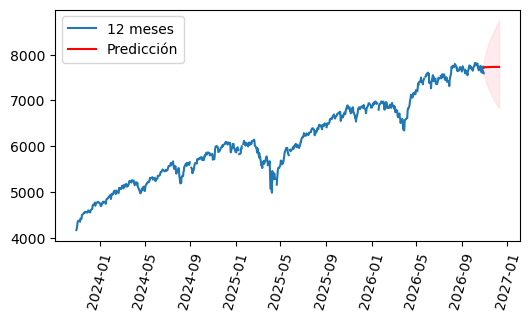

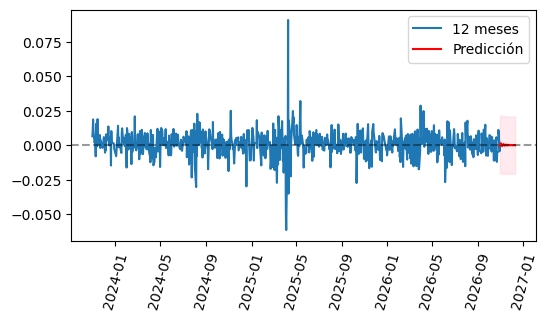

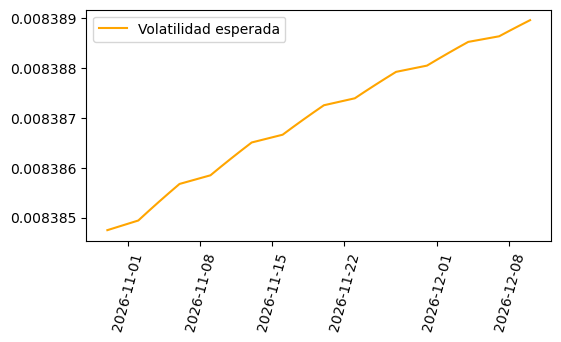

In [67]:
plt.figure(figsize=(6,3))
plt.plot(serie_precios.index, serie_precios, label="12 meses")
plt.plot(tabla['Fecha'], tabla['Precio'], color = "red", label = "Predicción")
plt.xticks(rotation = 75)
plt.fill_between(tabla['Fecha'],
                 tabla['Rango precios bajo'],
                 tabla['Rango precios alto'],
                 color="pink", alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(6,3))
plt.plot(serie_retornos.index, serie_retornos, label="12 meses")
plt.plot(tabla['Fecha'], tabla['Retorno_diario'], color="red", label= "Predicción")
plt.xticks(rotation = 75)
plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    alpha=0.4
)
plt.fill_between(tabla['Fecha'],
                 tabla['Rango retornos bajo'],
                 tabla['Rango retornos alto'],
                 color="pink", alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(6,3))
plt.plot(
    tabla['Fecha'],
    tabla['Volatilidad'],
    color="orange",
    label="Volatilidad esperada"
)
plt.xticks(rotation = 75)
plt.legend()
plt.show()

In [47]:
result

{'Fecha': Timestamp('2026-12-08 00:00:00'),
 'Precio': np.float64(7713.049144475049),
 'Retorno': np.float64(0.00030783590818872497),
 'Volatilidad_acumulada': np.float64(0.04605979509069321),
 'Ratio_Retorno_Riesgo': np.float64(0.006683397257469041)}

<p align="center"><b><font size="4">Entrenamiento de LSTM:</font></b></p>



Se entrena una red neuronal LSTM con un año del SP500. El entrenamiento se realizará con una ventana de 21 días que se recorrerá un día durante el año. La red consiste en una arquitectura LSTM de dos capas ocultas con 50 unidades ocultas (hidden units) y un entrenamiento de 100 épocas. Para comparar con el modelo SARIMAX se usan las mismas métricas,  RMSE, MAE y MAPE. 

In [10]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

In [30]:
daily_array_precios = np.log(daily_drop.iloc[-273:]).values.reshape(-1,1)
daily_array_retornos_ = np.log(daily_drop.iloc[-273:]).diff()
daily_array_retornos = daily_array_retornos_.dropna().values.reshape(-1,1)

scaler_precios = StandardScaler()
scaler_retornos = StandardScaler()

serie_precios = scaler_precios.fit_transform(daily_array_precios)
serie_retornos = scaler_retornos.fit_transform(daily_array_retornos)

secuencia = 21
horizonte = 1
xs_precios=[]
ys_precios=[]
xs_retornos=[]
ys_retornos=[]

resultados_lstm = []

for i in range(len(serie_precios)-secuencia-horizonte +1):
    x_ = serie_precios[i:(i+secuencia)]
    y_ = serie_precios[(i+secuencia):(i+secuencia+horizonte)]
    xs_precios.append(x_)
    ys_precios.append(y_)

x = np.array(xs_precios)
y = np.array(ys_precios)


x_train_precios, y_train_precios = x[:-21], y[:-21] 
x_test_precios, y_test_precios = x[-21:], y[-21:] 


x_train_precios = torch.tensor(x_train_precios, dtype=torch.float32)
y_train_precios = torch.tensor(y_train_precios, dtype=torch.float32)
x_test_precios = torch.tensor(x_test_precios, dtype=torch.float32)
y_test_precios = torch.tensor(y_test_precios, dtype=torch.float32)


for i in range(len(serie_retornos)-secuencia-horizonte +1):
    x_ = serie_retornos[i:(i+secuencia)]
    y_ = serie_retornos[(i+secuencia):(i+secuencia+horizonte)]
    xs_retornos.append(x_)
    ys_retornos.append(y_)

x = np.array(xs_retornos)
y = np.array(ys_retornos)

x_train_retornos, y_train_retornos = x[:-21], y[:-21] 
x_test_retornos, y_test_retornos = x[-21:], y[-21:] 

x_train_retornos = torch.tensor(x_train_retornos, dtype=torch.float32)
y_train_retornos = torch.tensor(y_train_retornos, dtype=torch.float32)
x_test_retornos = torch.tensor(x_test_retornos, dtype=torch.float32)
y_test_retornos = torch.tensor(y_test_retornos, dtype=torch.float32)

class LSTMModel(nn.Module):
    def __init__ (self, input_size = 1, hidden_size = 50, num_layers = 2, horizonte = 1):
        super(LSTMModel,self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first = True)
        self.fc = nn.Linear(hidden_size, horizonte )

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  
        out = self.fc(out)
        return out.unsqueeze(-1)

def entrenamiento(x_train, y_train, x_test, y_test, scaler, nombre):

    model = LSTMModel()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr= 0.005)
    
    epochs=100
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output= model(x_train)
        loss = criterion(output, y_train)
        loss.backward()
        optimizer.step()
        if epoch % 10 == 0:
            print(f" Ciclo: {epoch} | Pérdida: {loss.item()}")

    model.eval()
    with torch.no_grad():
        y_pred = model(x_test)
    
    y_test_inv = scaler.inverse_transform(y_test.numpy().reshape(-1,1))
    y_pred_inv = scaler.inverse_transform(y_pred.numpy().reshape(-1,1))
    
    rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
    mae = mean_absolute_error(y_test_inv, y_pred_inv)
    mape = (abs((y_test_inv- y_pred_inv) / y_test_inv).mean()) * 100


    
    resultados_lstm = {"Modelo": nombre,
    "RMSE": rmse,
    "MAE": mae,
    "MAPE": mape}

    return resultados_lstm, model

In [31]:
metricas_precios, model_precios = entrenamiento(x_train_precios, y_train_precios, x_test_precios, y_test_precios, scaler_precios, "LSTM_precios" )
metricas_retornos, model_retornos = entrenamiento(x_train_retornos, y_train_retornos, x_test_retornos, y_test_retornos, scaler_retornos, "LSTM_retornos")

 Ciclo: 0 | Pérdida: 0.8953944444656372
 Ciclo: 10 | Pérdida: 0.09346728771924973
 Ciclo: 20 | Pérdida: 0.085831418633461
 Ciclo: 30 | Pérdida: 0.07176859676837921
 Ciclo: 40 | Pérdida: 0.05688689276576042
 Ciclo: 50 | Pérdida: 0.044056281447410583
 Ciclo: 60 | Pérdida: 0.03921293467283249
 Ciclo: 70 | Pérdida: 0.03535394370555878
 Ciclo: 80 | Pérdida: 0.03295321390032768
 Ciclo: 90 | Pérdida: 0.030701832845807076
 Ciclo: 0 | Pérdida: 1.0118470191955566
 Ciclo: 10 | Pérdida: 0.9987775087356567
 Ciclo: 20 | Pérdida: 0.9713952541351318
 Ciclo: 30 | Pérdida: 0.9225059151649475
 Ciclo: 40 | Pérdida: 0.8939230442047119
 Ciclo: 50 | Pérdida: 0.8658533692359924
 Ciclo: 60 | Pérdida: 0.7928674221038818
 Ciclo: 70 | Pérdida: 0.712056577205658
 Ciclo: 80 | Pérdida: 0.6137338876724243
 Ciclo: 90 | Pérdida: 0.49273112416267395


Las métricas son comparables con SARIMAX. En precios tenemos que el error promedio, penalizando desviaciones muy grandes, es de RMSE: 0.008583 y sin esa penalización es de MAE: 0.007508, esas métricas son similares con los retornos. El porcentaje promedio de error es menor al 10% MAPE: 0.083854, en precios.   

Se realizó una prueba mediante predicción autoregresiva para evaluar la acumulación de errores, es deicr: el modelo recibe una ventana inicial de 21 observaciones y genera la predicción del día siguiente. Posteriormente, se conservan las 20 observaciones más recientes de la ventana y se incorpora la predicción obtenida para estimar el siguiente día. Este proceso se repite de forma iterativa hasta completar el horizonte de predicción solicitado.

In [32]:
resultados_lstm_acumulado = []

def metricas_acumulada(model, dias, x_test, y_test, scaler, nombre):

    ventana = x_test[0].clone()
    predicciones = []
    
    for _ in range(dias):
    
        with torch.no_grad():
            pred = model(ventana.unsqueeze(0))
    
        valor = pred.squeeze().item()
    
        predicciones.append(valor)
    
        nueva_ventana = ventana[1:]
        nuevo_valor = torch.tensor([[valor]], dtype=torch.float32)
    
        ventana = torch.cat([nueva_ventana, nuevo_valor], dim=0)

    y_test_inv = scaler.inverse_transform(y_test[:dias].numpy().reshape(-1,1))
    prediccione_inv = np.array(predicciones).reshape(-1,1)
    predicciones_inv = scaler.inverse_transform(prediccione_inv)
    
    rmse = np.sqrt(
        mean_squared_error(y_test_inv, predicciones_inv)
    )
    
    mae = mean_absolute_error(
        y_test_inv,
        predicciones_inv
    )
    
    mape = (
        np.abs(
            (y_test_inv - predicciones_inv)
            / y_test_inv
        ).mean()
    ) * 100
    
    resultados_lstm_acumulado = {"Modelo": nombre,
    "RMSE": rmse,
    "MAE": mae,
    "MAPE": mape}

    return resultados_lstm_acumulado

In [33]:
metricas_precios_acumulado = metricas_acumulada(model_precios, 21, x_test_precios, y_test_precios, scaler_precios, "LSTM_precios_acumulados")
metricas_retornos_acumulado = metricas_acumulada(model_retornos, 21, x_test_retornos, y_test_retornos, scaler_retornos, "LSTM_retornos_acumulados")

Comparando con las métricas sin acumular el error, en precios el MAPE es peor en un 0.6 y en retornos el MAE fue peor en un 0.006. Aunque es de esperar que las métricas disminuyan al acumular el error, la disminución está en rangos aceptables por lo que se puede desplegarse junto a SARIMAX para tener una comparativa en las predicciones, ya que cada modelo captura diferentes estructuras de los datos. 

<p align="center"><b><font size="4">Despliegue del modelo:</font></b></p>

El despliegue se divide en tres etapas.

**1. Reentrenamiento periódico**

Cada 15 días se descarga un nuevo conjunto de datos históricos del S&P 500. Posteriormente se realizan las transformaciones necesarias sobre precios y retornos, y se reentrena la red LSTM utilizando los parámetros seleccionados durante la fase de validación. Durante este proceso se almacenan las métricas de seguimiento del modelo: MAPE para precios y RMSE y MAE para retornos. Para la volatilidad se utilizará el GARCH empleado en SARIMAX, ya que la volatilidad es inherente a los datos y no al modelo.

**2. Actualización de datos**

Entre reentrenamientos, la aplicación descarga únicamente los datos más recientes y los incorpora a la serie histórica. Estos datos actualizados se almacenan en caché para evitar descargas y cálculos innecesarios cada vez que el usuario solicita una nueva predicción.

**3. Generación de predicciones**

Cuando el usuario selecciona un horizonte de predicción, la aplicación utiliza los modelos previamente entrenados para estimar:

- Precio esperado.
- Retorno diario esperado.
- Retorno acumulado esperado.
- Ratio retorno-riesgo.


In [31]:
df = yf.download('^GSPC', period='2y')
daily = df['Close'].resample("B").mean()
daily_drop = daily.dropna()

daily_array_precios = np.log(daily_drop.iloc[-273:]).values.reshape(-1,1)
daily_array_retornos_ = np.log(daily_drop.iloc[-273:]).diff()
daily_array_retornos = daily_array_retornos_.dropna().values.reshape(-1,1)

torch.manual_seed(42)
np.random.seed(42)

scaler_precios = StandardScaler()
scaler_retornos = StandardScaler()

serie_precios = scaler_precios.fit_transform(daily_array_precios)
serie_retornos = scaler_retornos.fit_transform(daily_array_retornos)

secuencia = 21
horizonte = 1
xs_precios=[]
ys_precios=[]
xs_retornos=[]
ys_retornos=[]

for i in range(len(serie_precios)-secuencia-horizonte +1):
    x_ = serie_precios[i:(i+secuencia)]
    y_ = serie_precios[(i+secuencia):(i+secuencia+horizonte)]
    xs_precios.append(x_)
    ys_precios.append(y_)

x = np.array(xs_precios)
y = np.array(ys_precios)

x_train_precios, y_train_precios = x[:-21], y[:-21] 
x_test_precios, y_test_precios = x[-21:], y[-21:] 


x_train_precios = torch.tensor(x_train_precios, dtype=torch.float32)
y_train_precios = torch.tensor(y_train_precios, dtype=torch.float32)
x_test_precios = torch.tensor(x_test_precios, dtype=torch.float32)
y_test_precios = torch.tensor(y_test_precios, dtype=torch.float32)


for i in range(len(serie_retornos)-secuencia-horizonte +1):
    x_ = serie_retornos[i:(i+secuencia)]
    y_ = serie_retornos[(i+secuencia):(i+secuencia+horizonte)]
    xs_retornos.append(x_)
    ys_retornos.append(y_)

x = np.array(xs_retornos)
y = np.array(ys_retornos)

x_train_retornos, y_train_retornos = x[:-21], y[:-21] 
x_test_retornos, y_test_retornos = x[-21:], y[-21:] 

x_train_retornos = torch.tensor(x_train_retornos, dtype=torch.float32)
y_train_retornos = torch.tensor(y_train_retornos, dtype=torch.float32)
x_test_retornos = torch.tensor(x_test_retornos, dtype=torch.float32)
y_test_retornos = torch.tensor(y_test_retornos, dtype=torch.float32)

class LSTMModel(nn.Module):
    def __init__ (self, input_size = 1, hidden_size = 50, num_layers = 2, horizonte = 1):
        super(LSTMModel,self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first = True)
        self.fc = nn.Linear(hidden_size, horizonte )

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  
        out = self.fc(out)
        return out.unsqueeze(-1)

def entrenamiento(x_train, y_train, x_test, y_test, scaler):

    model = LSTMModel()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr= 0.005)
    
    epochs=100
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output= model(x_train)
        loss = criterion(output, y_train)
        loss.backward()
        optimizer.step()
        if epoch % 10 == 0:
            print(f" Ciclo: {epoch} | Pérdida: {loss.item()}")

    model.eval()
    with torch.no_grad():
        y_pred = model(x_test)
    
    y_test_inv = scaler.inverse_transform(y_test.numpy().reshape(-1,1))
    y_pred_inv = scaler.inverse_transform(y_pred.numpy().reshape(-1,1))
    
    rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
    mae = mean_absolute_error(y_test_inv, y_pred_inv)
    mape = (abs((y_test_inv- y_pred_inv) / y_test_inv).mean()) * 100
    
    print("RMSE:", rmse)
    print("MAE:", mae)
    print("MAPE:", mape)

    return  model, scaler, rmse,  mae, mape
    

(model_precios, scaler_precios, rmse_precios, mae_precios, mape_precios) = entrenamiento(x_train_precios,
                                                                                       y_train_precios,x_test_precios,y_test_precios,scaler_precios)

(model_retornos, scaler_retornos, rmse_retornos, mae_retornos, mape_retornos) = entrenamiento(x_train_retornos, 
                                                                                             y_train_retornos,x_test_retornos,y_test_retornos,scaler_retornos)
fecha_actual = datetime.now().date()
ultima_fecha_hist = pd.to_datetime(daily.index[-1]).date()

df_nuevos_datos = yf.download('^GSPC', start=ultima_fecha_hist, end=fecha_actual, progress=False)
daily_nuevos = df_nuevos_datos['Close'].resample("B").mean().dropna()
daily_completo = pd.concat([daily, daily_nuevos])
daily_completo = daily_completo[~daily_completo.index.duplicated(keep="last")]

daily_precios = np.log(daily_completo).values.reshape(-1,1)
daily_retornos_ = np.log(daily_completo).diff()
daily_retornos = daily_retornos_.dropna().values.reshape(-1,1)

serie_precios_ = scaler_precios.transform(daily_precios)
serie_retornos_ = scaler_retornos.transform( daily_retornos)

serie_precios = np.array(serie_precios_)
serie_retornos = np.array(serie_retornos_)

precios_torch = torch.tensor(serie_precios, dtype=torch.float32)
retornos_torch  = torch.tensor(serie_retornos, dtype=torch.float32)

def predicciones_por_dia(model, dias, data, scaler):

    ventana = data[-21:].clone()
    predicciones = []
    
    for _ in range(dias):
    
        with torch.no_grad():
            pred = model(ventana.unsqueeze(0))
    
        valor = pred.squeeze().item()
    
        predicciones.append(valor)
    
        nueva_ventana = ventana[1:]
        nuevo_valor = torch.tensor([[valor]], dtype=torch.float32)
    
        ventana = torch.cat([nueva_ventana, nuevo_valor], dim=0)

   
    predicciones_inv = np.array(predicciones).reshape(-1,1)
    predicciones_inv = scaler.inverse_transform(predicciones_inv)
   

    future_dates = pd.date_range(
    start=daily_completo.index[-1] + pd.offsets.BusinessDay(1),
    periods=dias,
    freq="B")
    
    return  predicciones_inv, future_dates

pre_precios = predicciones_por_dia(model_precios, 10, precios_torch, scaler_precios)
pre_retornos = predicciones_por_dia(model_retornos, 10, retornos_torch, scaler_retornos)

predic_precios, calendario =  pre_precios
predic_retornos, calendario = pre_retornos

retorno_acumulado = (
    np.exp(
        predic_retornos.sum()
    ) - 1
)

predicciones_precio = np.exp(predic_precios)

[*********************100%***********************]  1 of 1 completed


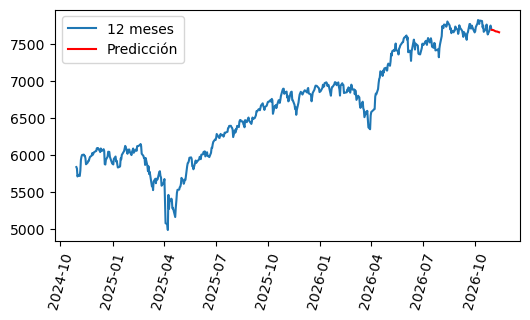

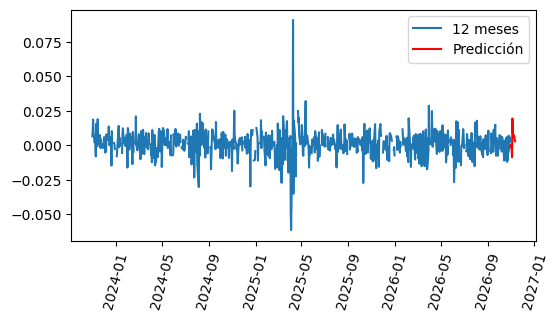

In [30]:
plt.figure(figsize=(6,3))
plt.plot(df.index, df['Close'], label="12 meses")
plt.plot(calendario, predicciones_precio, color = "red", label = "Predicción")
plt.xticks(rotation = 75)

plt.legend()
plt.show()

plt.figure(figsize=(6,3))
plt.plot(daily_retornos_.index, daily_retornos_, label="12 meses")
plt.plot(calendario, predic_retornos, color = "red", label = "Predicción")
plt.xticks(rotation = 75)

plt.legend()
plt.show()

In [38]:
datos= [modelo_precios_1_tears, modelo_retornos_1_tears, metricas_precios, metricas_retornos, metricas_precios_acumulado, metricas_retornos_acumulado]
tabla_modelos = pd.DataFrame(datos)
tabla_modelos = tabla_modelos.drop("Valor-p", axis=1)
tabla_modelos

,Modelo,RMSE,MAE,MAPE
0,Precios un año,0.012983,0.010868,0.120958
1,Retornos un año,0.006717,0.005540,134.634052
2,LSTM_precios,0.008583,0.007508,0.083854
3,LSTM_retornos,0.008383,0.006881,257.629181
4,LSTM_precios_acumulados,0.013789,0.012238,0.136639
5,LSTM_retornos_acumulados,0.012538,0.010564,482.131843


<p align="center"><b><font size="4">Conclusiones:</font></b></p>

- SARIMAX y LSTM mostraron puntajes similares en donde ninguna presentó una superioridad clara y consistente.
- Los modelos de SARIMAX entrenados con un año mostraron mejores métricas que con tres, lo que sugiere que para predicciones de días inmediatos los datos recientes son más relevantes. 
- Las pruebas realizadas con ventanas móviles mostraron que el desempeño de SARIMAX varía considerablemente dependiendo del periodo utilizado para la predicción, lo que indica que hay periodos cuya estructura es más compleja y por lo tanto menos propensa a predicciones, algo esperable en mercados financieros debido a la influencia de factores externos que no se encuentran contenidos en la serie temporal analizada. Lo anterior implica la necesidad de reentrenamiento constante con datos actualizados y el monitoreo de métricas claves.
- Aunque fue entrenada con alrededor de 250 datos LSTM mostró buenos resultados, caso que no se esperaba ya que estas redes suelen beneficiarse de una mayor cantidad de entradas.
- El entrenamiento de LSTM con ventanas de 21 días, transformaciones logarítmicas y horizonte de predicción de un día, la hizo competente a niveles de modelos clásicos.

La aplicación de los modelos se puede ver en esta liga: https://predicciones-del-sp500-con-sarimax-y-lstm-o9p8nwhhfnw5cc6sw4ap.streamlit.app/